## Мультивалютный портфель для сохранения покупательной способности
Система поддержки принятия решений для формирования мультивалютного портфеля
при ограничении на номинальную максимальную годовую просадку не выше 22 %
и доле нерублёвых инструментов не ниже 50 %.

Профили инвестора и их горизонты:
- резерв ликвидности — 6 месяцев;
- целевое накопление — 12 месяцев;
- сохранение капитала — 48 месяцев.

Вся расчётная логика вынесена в модуль `sppr_core.py`: тот же код использует дашборд `app.py`.
В ноутбуке расчёт выполняется пошагово, с промежуточными таблицами и графиками.

**Основные допущения**
- период: конец января 2015 — конец октября 2026, месячные данные;
- рублёвые денежные средства (`RUB_CASH`) приносят доход по ключевой ставке ЦБ РФ минус 1 п.п.
  (вклад или фонд денежного рынка); как меняются выводы при других допущениях, показано в разделе 6;
- портфель ежемесячно ребалансируется, комиссии и налоги не учитываются.

### 1. Исходные данные
Котировки Yahoo Finance: USD/RUB, EUR/RUB, USD/CNY, золото (`GC=F`), ETF `BIL` и `SHY`.
Месячный ряд строится из дневных данных (закрытие последнего торгового дня месяца):
в месячных барах yfinance у фьючерса на золото много пропусков.
Ряд сохранён в `data/prices_monthly.csv`, поэтому расчёт воспроизводим и не зависит от доступа к интернету.
Чтобы обновить данные, вызовите `load_monthly_prices(refresh=True)`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sppr_core as core
from sppr_core import PROFILES, PROFILE_LABELS, CASH

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

raw_all = core.load_monthly_prices()
raw = raw_all.loc[core.ANALYSIS_START:core.ANALYSIS_END]

print("Файл:", core.PRICES_PATH.name, "| размерность:", raw_all.shape)
print("Пропуски в периоде анализа:")
print(raw.isna().sum())
print("Период анализа:", raw.index.min().date(), "—", raw.index.max().date(), f"({len(raw)} мес.)")
print(raw.tail())

Файл: prices_monthly.csv | размерность: (143, 6)
Пропуски в периоде анализа:
RUB=X       0
EURRUB=X    0
CNY=X       0
GC=F        0
BIL         0
SHY         0
dtype: int64
Период анализа: 2015-01-01 — 2026-10-01 (142 мес.)
                RUB=X    EURRUB=X   CNY=X         GC=F        BIL        SHY
date                                                                        
2026-06-01  78.695427   89.814697  6.7936  4082.399902  90.560982  81.136665
2026-07-01  79.720741   91.869797  6.7550  4107.000000  90.866249  81.263512
2026-08-01  86.295425  100.251099  6.7260  4396.399902  91.117752  81.403671
2026-09-01  83.372162   94.434402  6.7045  4202.299805  91.376999  80.959000
2026-10-01  81.246338   90.856598  6.6610  3898.899902  91.699997  81.699997


### 2. Показатель сохранности покупательной способности
Котировки переводятся в рубли и очищаются от инфляции (помесячный ИПЦ РФ, Росстат).
Стоимость `RUB_CASH` растёт по средней за месяц ключевой ставке (`data/key_rate_ru.csv`) за вычетом 1 п.п.
Все индексы равны 1 в базовой точке — на конец января 2015.

In [2]:
market = core.load_market_data()
prices_nominal = market["prices_nominal"]
prices_real = market["prices_real"]
cpi = market["cpi"]

print("Номинальные рублёвые индексы (последние месяцы):")
print(prices_nominal.tail().round(3))
print("\nРост уровня цен за период:", round(cpi["cpi_index"].iloc[-1], 3))
cash_rate_annual = market["cash_rate"].iloc[1:] * 12 * 100
print(f"Доходность RUB_CASH: в среднем {cash_rate_annual.mean():.2f}% годовых "
      f"(от {cash_rate_annual.min():.2f}% до {cash_rate_annual.max():.2f}%)")
print("\nИзменение реальной стоимости за весь период, %:")
print(((prices_real.iloc[-1] - 1) * 100).round(2))

Номинальные рублёвые индексы (последние месяцы):
              USD    EUR    CNY   GOLD    BIL    SHY  RUB_CASH
date                                                          
2026-06-01  1.145  1.151  1.051  3.656  1.424  1.361     2.983
2026-07-01  1.160  1.178  1.071  3.726  1.447  1.381     3.016
2026-08-01  1.255  1.285  1.164  4.317  1.571  1.498     3.049
2026-09-01  1.213  1.211  1.128  3.987  1.522  1.439     3.082
2026-10-01  1.182  1.165  1.107  3.605  1.488  1.415     3.115

Рост уровня цен за период: 2.122
Доходность RUB_CASH: в среднем 9.72% годовых (от 3.25% до 20.00%)

Изменение реальной стоимости за весь период, %:
USD        -44.30
EUR        -45.11
CNY        -47.85
GOLD        69.86
BIL        -29.86
SHY        -33.30
RUB_CASH    46.81
Name: 2026-10-01 00:00:00, dtype: float64


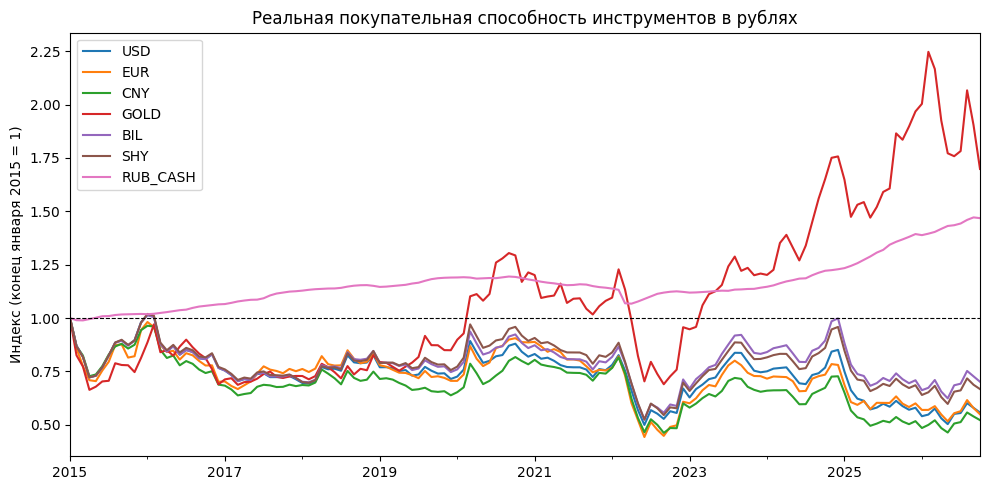

In [3]:
ax = prices_real.plot(figsize=(10, 5), title="Реальная покупательная способность инструментов в рублях")
ax.set_ylabel("Индекс (конец января 2015 = 1)")
ax.set_xlabel("")
ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--")
plt.tight_layout()
plt.show()

### 3. Рекомендательный отбор инструментов
Признаки считаются в реальном выражении:
- **волатильность** — годовое стандартное отклонение месячных доходностей;
- **максимальная годовая просадка** — худшая просадка внутри скользящего окна из 12 месяцев;
- **вероятность сохранения покупательной способности** — доля скользящих окон длиной в горизонт профиля,
  за которые реальная стоимость не снизилась (заменяет корреляцию с инфляцией: её значения были около нуля
  и статистически незначимы);
- **ликвидность** — экспертная оценка.

Признаки нормируются (min-max) только по шести нерублёвым инструментам. `RUB_CASH` в таблице приведён
справочно: в отборе он не участвует, потому что входит в портфель на этапе 5 как защитный полюс.
Интегральная оценка — взвешенная сумма нормированных признаков с весами профиля.
Отбираются инструменты с оценкой не ниже 0,5, но не меньше четырёх лучших.

In [4]:
features_by_profile, scores_by_profile, selected_instruments = {}, {}, {}

for profile, spec in PROFILES.items():
    features = core.compute_features(prices_real, spec["horizon"])
    normalized = core.normalize_features(features)
    scores = core.integral_score(normalized, spec["feature_weights"])
    selected = core.select_instruments(scores)

    features_by_profile[profile] = features
    scores_by_profile[profile] = scores
    selected_instruments[profile] = selected

    print(f"\n=== {spec['label']} (горизонт {spec['horizon']} мес.) ===")
    print(features.rename(columns={
        "volatility": "Волатильность",
        "drawdown": "Макс. годовая просадка",
        "preservation_probability": "Вероятность сохранения",
        "liquidity": "Ликвидность",
    }).round(3))
    print("Интегральная оценка:")
    print(scores.sort_values(ascending=False).round(3).to_string())
    print("Отобраны:", ", ".join(selected.index))


=== Резерв ликвидности (горизонт 6 мес.) ===
          Волатильность  Макс. годовая просадка  Вероятность сохранения  Ликвидность
USD               0.193                   0.396                   0.382         1.00
EUR               0.207                   0.461                   0.434         0.95
CNY               0.193                   0.434                   0.441         0.70
GOLD              0.238                   0.438                   0.625         0.85
BIL               0.194                   0.395                   0.419         0.90
SHY               0.195                   0.407                   0.456         0.90
RUB_CASH          0.024                   0.083                   0.787         1.00
Интегральная оценка:
USD     0.896
BIL     0.822
SHY     0.781
CNY     0.526
EUR     0.504
GOLD    0.310
Отобраны: USD, BIL, SHY, CNY, EUR

=== Целевое накопление (горизонт 12 мес.) ===
          Волатильность  Макс. годовая просадка  Вероятность сохранения  Ликвидность
USD

### 4. Формирование весов методом паритета риска
Паритет риска строится по отобранным нерублёвым инструментам. Ограничения: сумма весов равна 1,
доля одного инструмента не больше 40 %.
Рублёвый кеш сюда не входит: его дисперсия почти нулевая, и уравнять его вклад в риск
с остальными невозможно. Кеш подмешивается на следующем этапе.
Ковариация оценивается по номинальным рублёвым доходностям.

In [5]:
returns_nominal = prices_nominal.pct_change().dropna()
risk_parity_by_profile = {}

for profile, selected in selected_instruments.items():
    rp = core.risk_parity_weights(returns_nominal[list(selected.index)])
    risk_parity_by_profile[profile] = rp
    print(f"\n=== {PROFILE_LABELS[profile]} ===")
    print(pd.DataFrame({"Вес": rp["weights"], "Доля вклада в риск": rp["risk_contribution"]}).round(4))
    print("Годовая волатильность (номинальная, в рублях):", round(rp["volatility"], 3))


=== Резерв ликвидности ===


        Вес  Доля вклада в риск
USD  0.2017                 0.2
BIL  0.2006                 0.2
SHY  0.1996                 0.2
CNY  0.2033                 0.2
EUR  0.1949                 0.2
Годовая волатильность (номинальная, в рублях): 0.192

=== Целевое накопление ===
         Вес  Доля вклада в риск
USD   0.2576                0.25
BIL   0.2560                0.25
SHY   0.2542                0.25
GOLD  0.2322                0.25
Годовая волатильность (номинальная, в рублях): 0.193

=== Сохранение капитала ===
         Вес  Доля вклада в риск
GOLD  0.2322                0.25
BIL   0.2560                0.25
USD   0.2576                0.25
SHY   0.2542                0.25
Годовая волатильность (номинальная, в рублях): 0.193


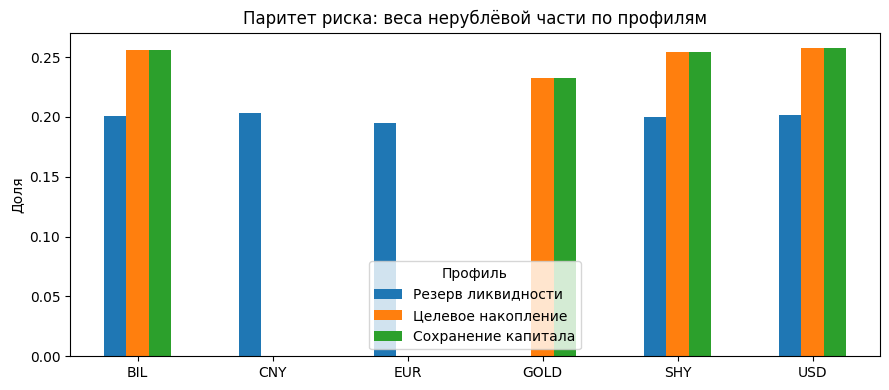

In [6]:
weights_table = pd.DataFrame({p: rp["weights"] for p, rp in risk_parity_by_profile.items()}).fillna(0.0)
ax = weights_table.rename(columns=PROFILE_LABELS).plot(
    kind="bar", figsize=(9, 4), title="Паритет риска: веса нерублёвой части по профилям"
)
ax.set_ylabel("Доля")
ax.set_xlabel("")
ax.legend(title="Профиль")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5. Граница «просадка — сохранность»
Портфель паритета риска (доля *m*) смешивается с рублёвым кешем (доля 1 − *m*), *m* меняется от 0 до 1 с шагом 0,01.
Для каждой точки рассчитываются:
- **показатель сохранности** — средний реальный множитель стоимости за горизонт профиля по всем скользящим окнам.
  Он меньше зависит от даты начала периода, чем одно значение на конец периода;
- вероятность сохранения и худший результат на горизонте;
- номинальная и реальная максимальная годовая просадка.

**Критерии выбора рекомендуемого портфеля:**
- номинальная максимальная годовая просадка не выше 22 %;
- доля нерублёвых инструментов не ниже 50 % (*m* ≥ 0,5);
- среди допустимых точек выбирается точка с максимальным показателем сохранности.

Доля одного нерублёвого инструмента в итоговом портфеле не превышает 40 %, потому что *m* ≤ 1.
Доля `RUB_CASH` ограничена требованием мультивалютности: не больше 50 %.

In [7]:
frontier_by_profile, recommendation = {}, {}

for profile, rp in risk_parity_by_profile.items():
    horizon = PROFILES[profile]["horizon"]
    frontier = core.build_frontier(rp["weights"], prices_nominal, prices_real, horizon)
    best, status, feasible = core.choose_portfolio(frontier)
    frontier_by_profile[profile] = frontier
    recommendation[profile] = best

    unconstrained = frontier.loc[frontier["preservation"].idxmax()]
    print(f"\n=== {PROFILE_LABELS[profile]} ===")
    print("Статус:", status)
    print("Доля паритета риска m:", best["mixing_coefficient"],
          "| без ограничений максимум сохранности при m =", unconstrained["mixing_coefficient"])
    print(f"Показатель сохранности (средний реальный множитель за {horizon} мес.):", round(best["preservation"], 3))
    print("Вероятность сохранения на горизонте:", round(best["preservation_probability"], 3))
    print("Худший результат на горизонте:", round(best["worst_horizon"], 3))
    print("Реальная стоимость за весь период:", round(best["full_period"], 3))
    print("Номинальная годовая просадка:", round(best["nominal_drawdown"], 3))
    print("Реальная годовая просадка (справочно):", round(best["real_drawdown"], 3))
    print("Рекомендуемые веса:")
    print(best["weights"].round(3).to_string())
    print("Валютная структура:")
    print(core.currency_exposure(best["weights"]).round(3).to_string())

recommended_weights = {p: r["weights"] for p, r in recommendation.items()}
print()
print(pd.DataFrame(recommended_weights).reindex(core.ALL_ASSETS).fillna(0.0).rename(columns=PROFILE_LABELS).round(3))


=== Резерв ликвидности ===
Статус: номинальная просадка ≤ 22% и доля нерублёвых инструментов ≥ 50%
Доля паритета риска m: 0.5 | без ограничений максимум сохранности при m = 0.0
Показатель сохранности (средний реальный множитель за 6 мес.): 1.006
Вероятность сохранения на горизонте: 0.537
Худший результат на горизонте: 0.786
Реальная стоимость за весь период: 0.991
Номинальная годовая просадка: 0.177
Реальная годовая просадка (справочно): 0.245
Рекомендуемые веса:
USD         0.101
BIL         0.100
SHY         0.100
CNY         0.102
EUR         0.097
RUB_CASH    0.500
Валютная структура:
USD       0.301
EUR       0.097
CNY       0.102
Золото    0.000
RUB       0.500

=== Целевое накопление ===
Статус: номинальная просадка ≤ 22% и доля нерублёвых инструментов ≥ 50%
Доля паритета риска m: 0.5 | без ограничений максимум сохранности при m = 0.0
Показатель сохранности (средний реальный множитель за 12 мес.): 1.025
Вероятность сохранения на горизонте: 0.646
Худший результат на горизонте: 0

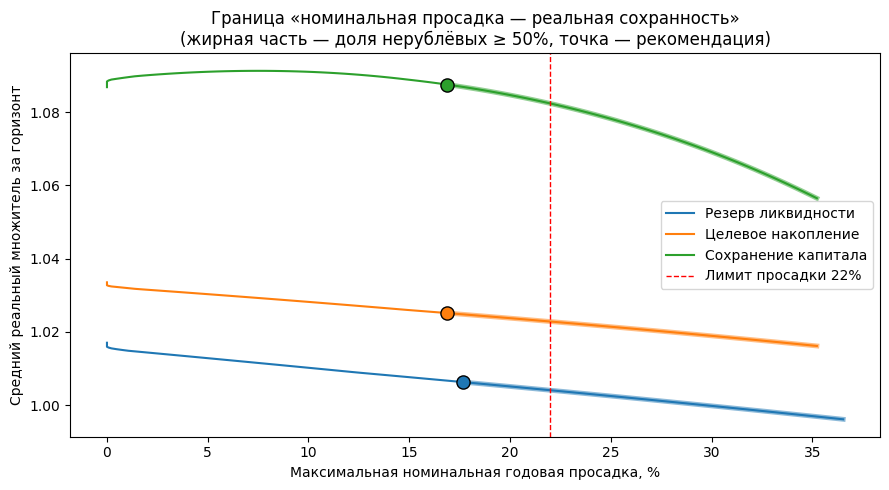

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for profile, frontier in frontier_by_profile.items():
    line, = ax.plot(frontier["nominal_drawdown"] * 100, frontier["preservation"], label=PROFILE_LABELS[profile])
    allowed = frontier[frontier["non_cash_share"] >= core.MIN_NON_CASH_SHARE - 1e-9]
    ax.plot(allowed["nominal_drawdown"] * 100, allowed["preservation"], color=line.get_color(), linewidth=3.5, alpha=0.5)
    best = recommendation[profile]
    ax.scatter([best["nominal_drawdown"] * 100], [best["preservation"]], s=90, zorder=5,
               color=line.get_color(), edgecolor="black")

ax.axvline(core.DRAWDOWN_LIMIT * 100, color="red", linestyle="--", linewidth=1,
           label=f"Лимит просадки {core.DRAWDOWN_LIMIT:.0%}")
ax.set_xlabel("Максимальная номинальная годовая просадка, %")
ax.set_ylabel("Средний реальный множитель за горизонт")
ax.set_title("Граница «номинальная просадка — реальная сохранность»\n(жирная часть — доля нерублёвых ≥ 50%, точка — рекомендация)")
ax.legend()
plt.tight_layout()
plt.show()

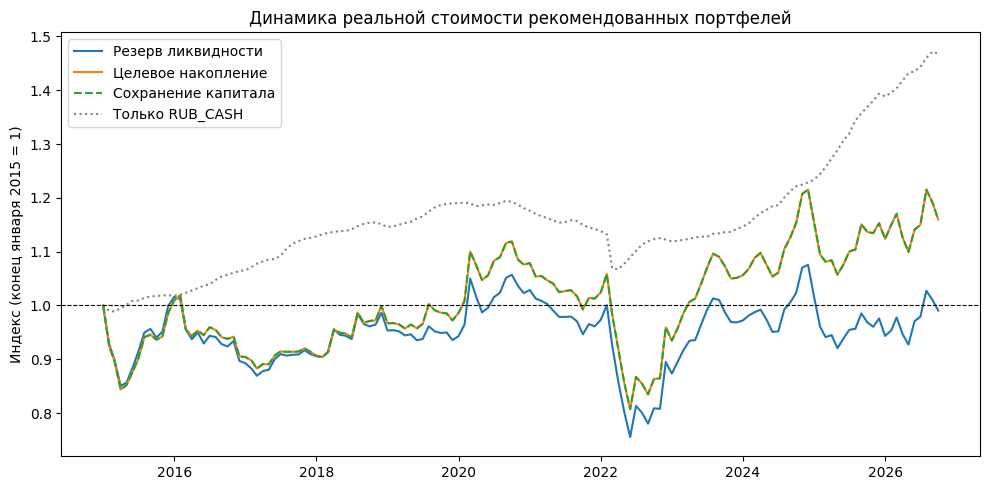

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
line_styles = {"liquidity_reserve": "-", "target_accumulation": "-", "capital_preservation": "--"}
for profile, weights in recommended_weights.items():
    path = core.portfolio_path(weights, prices_real)
    ax.plot(path.index, path.values, linestyle=line_styles[profile], label=PROFILE_LABELS[profile])
ax.plot(prices_real.index, prices_real[CASH], color="grey", linestyle=":", label="Только RUB_CASH")
ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Динамика реальной стоимости рекомендованных портфелей")
ax.set_ylabel("Индекс (конец января 2015 = 1)")
ax.legend()
plt.tight_layout()
plt.show()

### 6. Анализ чувствительности
Рекомендация сильно зависит от допущения о доходности рублёвых средств. Ниже модель пересчитана для
нескольких вариантов: кеш без процентов (допущение первой версии работы) и ключевая ставка минус 4, 2, 1 и 0 п.п.
Отдельно показано, какую минимальную номинальную просадку можно получить при доле нерублёвых ровно 50 %:
это нижняя граница для лимита просадки.

In [10]:
sensitivity_rows = []
for label, spread in [("без процентов", None), ("ключевая − 4 п.п.", 4.0), ("ключевая − 2 п.п.", 2.0),
                      ("ключевая − 1 п.п. (базовый)", 1.0), ("ключевая ставка", 0.0)]:
    model = core.run_model(cash_spread=spread)
    cash_real = model["market"]["prices_real"][CASH].iloc[-1]
    for profile, item in model["profiles"].items():
        best = item["best"]
        sensitivity_rows.append({
            "Доходность кеша": label,
            "Реальная стоимость кеша за период": round(cash_real, 3),
            "Профиль": PROFILE_LABELS[profile],
            "Доля RUB_CASH": round(best["weights"][CASH], 2),
            "Сохранность": round(best["preservation"], 3),
            "Вероятность сохранения": round(best["preservation_probability"], 3),
            "Номинальная просадка": round(best["nominal_drawdown"], 3),
            "Ограничения выполнены": "да" if item["feasible"] else "нет",
        })
sensitivity = pd.DataFrame(sensitivity_rows)
print(sensitivity.to_string(index=False))

print("\nМинимальная номинальная годовая просадка при доле нерублёвых 50% (базовое допущение):")
for profile, frontier in frontier_by_profile.items():
    at_half = frontier.loc[(frontier["mixing_coefficient"] - core.MIN_NON_CASH_SHARE).abs().idxmin()]
    print(f"  {PROFILE_LABELS[profile]}: {at_half['nominal_drawdown']:.1%}")

            Доходность кеша  Реальная стоимость кеша за период             Профиль  Доля RUB_CASH  Сохранность  Вероятность сохранения  Номинальная просадка Ограничения выполнены
              без процентов                              0.471  Резерв ликвидности           0.44        0.984                   0.375                 0.219                    да
              без процентов                              0.471  Целевое накопление           0.42        0.984                   0.385                 0.217                    да
              без процентов                              0.471 Сохранение капитала           0.42        0.944                   0.319                 0.217                    да
          ключевая − 4 п.п.                              1.034  Резерв ликвидности           0.50        0.999                   0.441                 0.181                    да
          ключевая − 4 п.п.                              1.034  Целевое накопление           0.38        

### 7. Стресс-тестирование
К истории добавляется один шоковый месяц. Показаны номинальный и реальный результат этого месяца
и номинальная просадка за последние 12 месяцев с учётом шока: соблюдается ли после шока ограничение 22 %.
Инфляционный шок повторяет март 2022 года: цены выросли на 7,6 % за месяц. Именно этот сценарий
опасен для рублёвой части портфеля.

In [11]:
stress_tables = []
for profile, weights in recommended_weights.items():
    table = core.stress_test(weights, prices_nominal, prices_real)
    table.insert(0, "Профиль", PROFILE_LABELS[profile])
    stress_tables.append(table)
stress_table = pd.concat(stress_tables, ignore_index=True)

formatted = stress_table.copy()
for column in ["Номинальный результат месяца", "Реальный результат месяца"]:
    formatted[column] = formatted[column].map(lambda v: "—" if pd.isna(v) else f"{v:+.1%}")
column = "Номинальная просадка за 12 мес. с шоком"
formatted[column] = formatted[column].map(lambda v: f"{v:.1%}")
print(formatted.to_string(index=False))

            Профиль                                            Сценарий Номинальный результат месяца Реальный результат месяца Номинальная просадка за 12 мес. с шоком Лимит просадки соблюдён
 Резерв ликвидности                        Без шока (последние 12 мес.)                            —                         —                                    4.9%                      да
 Резерв ликвидности                       Ослабление USD к рублю на 20%                        -6.0%                     -6.0%                                    7.9%                      да
 Резерв ликвидности                       Ослабление EUR к рублю на 20%                        -1.9%                     -1.9%                                    4.9%                      да
 Резерв ликвидности                       Ослабление CNY к рублю на 20%                        -2.0%                     -2.0%                                    4.9%                      да
 Резерв ликвидности                     Совме

### 8. Сверка паритета риска с Excel Solver
Для профиля «Резерв ликвидности» создаётся книга `data/solver_rp.xlsx`: ковариационная матрица,
вклады в риск формулами Excel и целевая ячейка. Порядок запуска Solver описан на листе «Инструкция».
После запуска Solver и сохранения книги эта ячейка сравнит веса Excel с весами Python.
Книга пересоздаётся, только если изменился состав инструментов, поэтому результат Solver не затирается.

In [12]:
profile_to_check = "liquidity_reserve"
rp_check = risk_parity_by_profile[profile_to_check]
assets_check = list(rp_check["weights"].index)

existing = core.read_solver_weights()
if existing is None or list(existing.index) != assets_check:
    core.write_solver_workbook(rp_check["covariance"], rp_check["weights"])
    print("Создана книга:", core.SOLVER_PATH.relative_to(core.BASE_DIR))

comparison, solver_status = core.solver_comparison(rp_check["weights"], rp_check["covariance"])
print("Инструменты:", assets_check)
print("Статус:", solver_status)
if comparison is not None:
    print(comparison.round(4))
else:
    print("Веса Python:")
    print(rp_check["weights"].round(4).to_string())

Инструменты: ['USD', 'BIL', 'SHY', 'CNY', 'EUR']
Статус: Максимальное расхождение весов: 1.10e-08
     Python  Excel Solver  Разница  Вклад в риск (Solver)
USD  0.2017        0.2017      0.0                    0.2
BIL  0.2006        0.2006     -0.0                    0.2
SHY  0.1996        0.1996      0.0                    0.2
CNY  0.2033        0.2033      0.0                    0.2
EUR  0.1949        0.1949     -0.0                    0.2


### 9. Интерактивная визуализация (Plotly Dash)

Дашборд вынесен в отдельный файл `app.py`, чтобы его было удобно показывать на защите.
Он использует тот же модуль `sppr_core.py` и локальные данные из папки `data/`, интернет для запуска не нужен.

**Что показывает интерфейс**
- выбор профиля инвестора;
- показатели сохранности и просадки;
- веса и валютную структуру рекомендованного портфеля;
- границу «просадка — сохранность»;
- динамику реальной стоимости;
- таблицу рекомендательного отбора;
- результаты стресс-тестирования;
- сверку с Excel Solver (после запуска Solver).

**Запуск** (в терминале из папки проекта):
```bash
python app.py
```
Затем откройте в браузере: http://127.0.0.1:8050

Остановка: `Ctrl+C` в терминале.

In [13]:
from pathlib import Path

print("Файл дашборда на месте:", Path("app.py").exists())
print("Запуск: python app.py, затем откройте http://127.0.0.1:8050")

Файл дашборда на месте: True
Запуск: python app.py, затем откройте http://127.0.0.1:8050
